# LitNet — Ablation Study (Reviewed Version)

**Purpose:** Systematically vary individual design choices of the LitUNet-DLU baseline.

**Ablation axes:**
1. Activation function (ReLU / LeakyReLU / DLU)
2. Loss function (BCE / Dice / Combined α ∈ {0.3, 0.5, 0.7})
3. Bottleneck dropout rate (0.0 / 0.2 / 0.4 / 0.6)
4. Batch normalization (on / off)
5. Network width (Small / Base / Large)
6. DLU β upper bound (0.01 / 0.1 / 0.3)

**Methodological safeguards in this version:**
- Corrupt or unmatched image-mask pairs are excluded and reported before training.
- A deterministic validation split is created from the training directory; the test set is kept separate.
- Ablation configurations are compared on validation data only. Do not use test results to select a configuration.
- Binary masks are normalized before thresholding.
- Metrics are computed from thresholded predictions; Keras `MeanIoU` is not used on sigmoid probabilities.
- Old result files without the current experiment version are not reused as valid cache entries.

**Important:** Run the notebook from top to bottom in a fresh runtime. This file has intentionally cleared saved outputs because the previous outputs included a failed training run and results generated by the earlier evaluation pipeline.

In [1]:
# ============================================================
# 1. SETUP & IMPORTS (Colab)
# ============================================================
import os, gc, time, json, random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel
from sklearn.metrics import precision_recall_fscore_support
from IPython.display import display, Javascript

# --- Colab keep-alive (auto-click reconnect) ---
display(Javascript('''
function ClickConnect(){
  console.log("keep-alive ping");
  document.querySelector("colab-toolbar-button#connect")?.click();
}
setInterval(ClickConnect, 60000);
'''))

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

<IPython.core.display.Javascript object>

TF: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ============================================================
# MOUNT DRIVE + STAGE DATA LOCALLY
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# ⚠️ EDIT THIS to match your actual Drive path
DRIVE_DATASET = "/content/drive/MyDrive/data_wound_seg"
# e.g. "/content/drive/MyDrive/Colab Notebooks/datasets/data_wound_seg"

LOCAL_DATASET = "/content/data_wound_seg"

# Copy once (fast because it's on Drive, only runs first time)
if not os.path.exists(LOCAL_DATASET):
    print("📥 Copying dataset from Drive to local disk...")
    !cp -r "{DRIVE_DATASET}" "{LOCAL_DATASET}"
    print("✅ Copied.")
else:
    print("✅ Local dataset already present (skipping copy).")

# Save ablation outputs back to Drive (so they survive Colab resets)
DRIVE_OUT = "/content/drive/MyDrive/litnet_ablation"
os.makedirs(DRIVE_OUT, exist_ok=True)
print("📁 Outputs will be mirrored to:", DRIVE_OUT)

Mounted at /content/drive
📥 Copying dataset from Drive to local disk...
✅ Copied.
📁 Outputs will be mirrored to: /content/drive/MyDrive/litnet_ablation


In [3]:
# ============================================================
# 2. PATHS & GLOBAL ABLATION CONFIG
# ============================================================
IMG_PATH       = f"{LOCAL_DATASET}/train_images"
MASK_PATH      = f"{LOCAL_DATASET}/train_masks"
TEST_IMG_PATH  = f"{LOCAL_DATASET}/test_images"
TEST_MASK_PATH = f"{LOCAL_DATASET}/test_masks"

ABLATION_DIR = "ablation_results"
CKPT_DIR     = "ablation_ckpts"
os.makedirs(ABLATION_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

IMG_SIZE        = 128
BATCH_SIZE      = 16
EPOCHS          = 30
# This notebook executes one run per configuration. For inferential statistics,
# repeat the full experiment with independent seeds and retain per-run results.
LR              = 1e-4
VALIDATION_FRACTION = 0.20
EXPERIMENT_VERSION = "reviewed_v2_validation_only"

for p in [IMG_PATH, MASK_PATH, TEST_IMG_PATH, TEST_MASK_PATH]:
    n = len(os.listdir(p)) if os.path.exists(p) else "MISSING"
    print(f"{p:55s} → {n}")

missing = [p for p in [IMG_PATH, MASK_PATH, TEST_IMG_PATH, TEST_MASK_PATH]
           if not os.path.isdir(p)]
if missing:
    raise FileNotFoundError("Dataset folder(s) missing: " + ", ".join(missing))

/content/data_wound_seg/train_images                    → 2208
/content/data_wound_seg/train_masks                     → 2208
/content/data_wound_seg/test_images                     → 559
/content/data_wound_seg/test_masks                      → 552


In [4]:
# ============================================================
# SYNC HELPER — mirror CSV + checkpoints to Drive
# ============================================================
import shutil

def sync_to_drive():
    """Copy all ablation results & checkpoints to Drive."""
    for f in os.listdir(ABLATION_DIR):
        source = os.path.join(ABLATION_DIR, f)
        if os.path.isfile(source):
            shutil.copy2(source, os.path.join(DRIVE_OUT, f))
    ckpt_out = os.path.join(DRIVE_OUT, "ckpts")
    os.makedirs(ckpt_out, exist_ok=True)
    for f in os.listdir(CKPT_DIR):
        source = os.path.join(CKPT_DIR, f)
        if os.path.isfile(source):
            shutil.copy2(source, os.path.join(ckpt_out, f))
    print(f"💾 Synced {len(os.listdir(ABLATION_DIR))} CSVs + "
          f"{len(os.listdir(CKPT_DIR))} ckpts → {DRIVE_OUT}")

In [5]:
# ============================================================
# RESTORE ONLY RESULTS FROM THE CURRENT EXPERIMENT VERSION
# ============================================================
# Previous CSVs are preserved in a legacy folder, not silently mixed
# with results generated using the corrected evaluation protocol.
legacy_dir = os.path.join(ABLATION_DIR, "legacy_results")
os.makedirs(legacy_dir, exist_ok=True)
for f in os.listdir(ABLATION_DIR):
    local_fp = os.path.join(ABLATION_DIR, f)
    if not f.endswith(".csv") or f == "master.csv":
        continue
    try:
        old = pd.read_csv(local_fp)
        compatible = ("experiment_version" in old.columns and
                      old["experiment_version"].astype(str).eq(EXPERIMENT_VERSION).all())
    except Exception:
        compatible = False
    if not compatible:
        target = os.path.join(legacy_dir, f)
        if os.path.exists(target):
            stem, ext = os.path.splitext(f)
            target = os.path.join(legacy_dir, f"{stem}_{int(time.time())}{ext}")
        shutil.move(local_fp, target)

restored = 0
ckpt_src = os.path.join(DRIVE_OUT, "ckpts") if "DRIVE_OUT" in globals() else None
if os.path.isdir(DRIVE_OUT):
    for f in os.listdir(DRIVE_OUT):
        if not f.endswith(".csv") or f == "master.csv":
            continue
        fp = os.path.join(DRIVE_OUT, f)
        try:
            candidate = pd.read_csv(fp)
            compatible = ("experiment_version" in candidate.columns and
                          candidate["experiment_version"].astype(str).eq(EXPERIMENT_VERSION).all())
        except Exception:
            compatible = False
        if compatible:
            shutil.copy2(fp, os.path.join(ABLATION_DIR, f))
            restored += 1
    if ckpt_src and os.path.isdir(ckpt_src):
        for f in os.listdir(ckpt_src):
            shutil.copy2(os.path.join(ckpt_src, f), os.path.join(CKPT_DIR, f))
print(f"Restored {restored} compatible result CSV(s). Legacy CSVs, if any, are preserved separately.")

Restored 0 compatible result CSV(s). Legacy CSVs, if any, are preserved separately.


In [6]:
# ============================================================
# DATASET ALIGNMENT + FILE INTEGRITY CHECK
# ============================================================
from PIL import Image
from collections import Counter

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp")

def make_valid_pairs(img_dir, mask_dir, tag=""):
    """Return readable, basename-matched image/mask path pairs; report exclusions."""
    imgs = {os.path.splitext(f)[0]: f for f in os.listdir(img_dir)
            if f.lower().endswith(IMAGE_EXTS)}
    masks = {os.path.splitext(f)[0]: f for f in os.listdir(mask_dir)
             if f.lower().endswith(IMAGE_EXTS)}
    common = sorted(set(imgs) & set(masks))
    img_only = sorted(set(imgs) - set(masks))
    mask_only = sorted(set(masks) - set(imgs))
    valid, unreadable = [], []

    for name in common:
        ip = os.path.join(img_dir, imgs[name])
        mp = os.path.join(mask_dir, masks[name])
        try:
            with Image.open(ip) as im:
                im.verify()
            with Image.open(mp) as im:
                im.verify()
            valid.append((name, ip, mp))
        except Exception as exc:
            unreadable.append((name, str(exc)))

    print(f"[{tag}] images={len(imgs)} masks={len(masks)} basename_matches={len(common)}")
    print(f"[{tag}] valid_pairs={len(valid)} image_without_mask={len(img_only)} mask_without_image={len(mask_only)} unreadable_pairs={len(unreadable)}")
    if img_only:
        print("  Image without mask (first 10):", img_only[:10])
    if mask_only:
        print("  Mask without image (first 10):", mask_only[:10])
    if unreadable:
        print("  Unreadable pairs (first 10):", unreadable[:10])
    if not valid:
        raise ValueError(f"No valid image-mask pairs found for {tag}.")
    return [(ip, mp) for _, ip, mp in valid]

train_pairs_all = make_valid_pairs(IMG_PATH, MASK_PATH, "TRAIN SOURCE")
test_pairs = make_valid_pairs(TEST_IMG_PATH, TEST_MASK_PATH, "TEST")

# Deterministic split: validation is drawn only from the training directory.
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(train_pairs_all))
n_val = max(1, int(round(len(train_pairs_all) * VALIDATION_FRACTION)))
if len(train_pairs_all) - n_val < 1:
    raise ValueError("Not enough valid training pairs for a train/validation split.")
val_idx = set(indices[:n_val].tolist())
train_pairs = [pair for i, pair in enumerate(train_pairs_all) if i not in val_idx]
val_pairs = [pair for i, pair in enumerate(train_pairs_all) if i in val_idx]
print(f"Split sizes: train={len(train_pairs)}, validation={len(val_pairs)}, held-out test={len(test_pairs)}")

[TRAIN SOURCE] images=2208 masks=2208 basename_matches=2208
[TRAIN SOURCE] valid_pairs=2206 image_without_mask=0 mask_without_image=0 unreadable_pairs=2
  Unreadable pairs (first 10): [('wsnet_0035', "cannot identify image file '/content/data_wound_seg/train_images/wsnet_0035.png'"), ('wsnet_1079', "broken PNG file (bad header checksum in b'IDAT')")]
[TEST] images=558 masks=552 basename_matches=552
[TEST] valid_pairs=551 image_without_mask=6 mask_without_image=0 unreadable_pairs=1
  Image without mask (first 10): ['fusc_0594 (1)', 'fusc_0600 (1)', 'fusc_0603 (1)', 'fusc_0605 (1)', 'fusc_0607 (1)', 'fusc_0612 (1)']
  Unreadable pairs (first 10): [('fusc_0882', "broken PNG file (bad header checksum in b'IDAT')")]
Split sizes: train=1765, validation=441, held-out test=551


In [7]:
# ============================================================
# PREPROCESSING & AUGMENTATION
# ============================================================
def preprocess_image(image):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), method="bilinear")
    return tf.cast(image, tf.float32) / 255.0

def preprocess_mask(mask):
    # decode_image returns uint8 for common image formats. Normalize before thresholding.
    mask = tf.image.resize(mask, (IMG_SIZE, IMG_SIZE), method="nearest")
    mask = tf.cast(mask, tf.float32) / 255.0
    return tf.cast(mask >= 0.5, tf.float32)

def augment_image_and_mask(image, mask, seed):
    """Apply identical geometric transforms to image/mask; vary seed by sample."""
    s = tf.cast(seed, tf.int32)
    image = tf.image.stateless_random_flip_left_right(image, s)
    mask  = tf.image.stateless_random_flip_left_right(mask, s)
    s2 = s + tf.constant([1, 0], dtype=tf.int32)
    image = tf.image.stateless_random_flip_up_down(image, s2)
    mask  = tf.image.stateless_random_flip_up_down(mask, s2)
    s3 = s + tf.constant([2, 0], dtype=tf.int32)
    image = tf.image.stateless_random_brightness(image, max_delta=0.1, seed=s3)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, mask

def _decode_any(path, channels):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=channels, expand_animations=False)
    image.set_shape([None, None, channels])
    return image

def load_image_mask(img_path, mask_path, seed):
    image = preprocess_image(_decode_any(img_path, 3))
    mask = preprocess_mask(_decode_any(mask_path, 1))
    return augment_image_and_mask(image, mask, seed)

In [8]:
# ============================================================
# DATASET BUILDER + EXPLICIT TRAIN / VALIDATION / TEST DATASETS
# ============================================================
def create_dataset(pairs, batch_size=BATCH_SIZE, shuffle=False, augment=False):
    if not pairs:
        raise ValueError("Cannot create a dataset from zero image-mask pairs.")
    image_paths = [p[0] for p in pairs]
    mask_paths = [p[1] for p in pairs]
    ds = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if shuffle:
        ds = ds.shuffle(len(pairs), seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.enumerate()
        def _load_aug(index, pair):
            # Unique deterministic seed per sample. Augmentation is reproducible across runs.
            seed = tf.stack([tf.cast(SEED, tf.int32), tf.cast(index, tf.int32)])
            return load_image_mask(pair[0], pair[1], seed)
        ds = ds.map(_load_aug, num_parallel_calls=tf.data.AUTOTUNE,
                    deterministic=True)
    else:
        def _load_eval(img_path, mask_path):
            image = preprocess_image(_decode_any(img_path, 3))
            mask = preprocess_mask(_decode_any(mask_path, 1))
            return image, mask
        ds = ds.map(_load_eval, num_parallel_calls=tf.data.AUTOTUNE,
                    deterministic=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_pairs, shuffle=True, augment=True)
val_ds   = create_dataset(val_pairs, shuffle=False, augment=False)
test_ds  = create_dataset(test_pairs, shuffle=False, augment=False)

print("Dataset batches:", {
    "train": tf.data.experimental.cardinality(train_ds).numpy(),
    "validation": tf.data.experimental.cardinality(val_ds).numpy(),
    "test": tf.data.experimental.cardinality(test_ds).numpy(),
})

Dataset batches: {'train': np.int64(111), 'validation': np.int64(28), 'test': np.int64(35)}


In [9]:
# ============================================================
# OPTIONAL FILE FORMAT AUDIT
# ============================================================
def scan_formats(folder, tag):
    ext_counter, actual_counter, unreadable = Counter(), Counter(), []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTS))
    for filename in files:
        ext_counter[os.path.splitext(filename)[1].lower()] += 1
        try:
            with Image.open(os.path.join(folder, filename)) as im:
                actual_counter[(im.format or "unknown").lower()] += 1
                im.verify()
        except Exception as exc:
            unreadable.append((filename, str(exc)))
    print(f"{tag}: extensions={dict(ext_counter)} actual_formats={dict(actual_counter)} unreadable={len(unreadable)}")
    if unreadable:
        print("Unreadable examples:", unreadable[:10])
    return unreadable

# The pair-integrity check above already excludes unreadable matched pairs.
# This audit is informational and does not silently modify the dataset.
scan_formats(IMG_PATH, "TRAIN IMAGES")
scan_formats(MASK_PATH, "TRAIN MASKS")
scan_formats(TEST_IMG_PATH, "TEST IMAGES")
scan_formats(TEST_MASK_PATH, "TEST MASKS")

TRAIN IMAGES: extensions={'.png': 2208} actual_formats={'png': 2207} unreadable=2
Unreadable examples: [('wsnet_0035.png', "cannot identify image file '/content/data_wound_seg/train_images/wsnet_0035.png'"), ('wsnet_1079.png', "broken PNG file (bad header checksum in b'IDAT')")]
TRAIN MASKS: extensions={'.png': 2208} actual_formats={'png': 2208} unreadable=0
TEST IMAGES: extensions={'.png': 558} actual_formats={'png': 558} unreadable=1
Unreadable examples: [('fusc_0882.png', "broken PNG file (bad header checksum in b'IDAT')")]
TEST MASKS: extensions={'.png': 552} actual_formats={'png': 552} unreadable=0


[]

In [10]:
# ============================================================
# CELL 9 — METRICS & LOSSES
# ============================================================
def dice_loss(y_true, y_pred, smooth=1e-6):
    yt = tf.reshape(y_true, [-1]); yp = tf.reshape(y_pred, [-1])
    inter = tf.reduce_sum(yt * yp)
    return 1 - (2.*inter + smooth) / (tf.reduce_sum(yt) + tf.reduce_sum(yp) + smooth)

def dice_coefficient(y_true, y_pred, smooth=1e-6):
    yt = tf.reshape(y_true, [-1]); yp = tf.reshape(y_pred, [-1])
    inter = tf.reduce_sum(yt * yp)
    return (2.*inter + smooth) / (tf.reduce_sum(yt) + tf.reduce_sum(yp) + smooth)

def bce_only(y_true, y_pred, **kw):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    return tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))

def dice_only(y_true, y_pred, **kw):
    return dice_loss(y_true, y_pred)

def combined_loss(y_true, y_pred, alpha=0.5, smooth=1e-6):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return alpha * bce + (1 - alpha) * dice_loss(y_true, y_pred, smooth)

def combined_alpha(alpha):
    def _loss(y_true, y_pred, **kw):
        return combined_loss(y_true, y_pred, alpha=alpha)
    return _loss

In [11]:
# ============================================================
# CELL 10 — DLU ACTIVATION LAYER
# ============================================================
from tensorflow.keras import layers, models

class DLU(layers.Layer):
    def __init__(self, beta_init=0.0, beta_max=0.01, **kwargs):
        super().__init__(**kwargs)
        self.beta_init = beta_init
        self.beta_max  = beta_max

    def build(self, input_shape):
        self.beta = self.add_weight(
            name="beta", shape=(1,),
            initializer=tf.keras.initializers.Constant(self.beta_init),
            trainable=True,
            constraint=tf.keras.constraints.MinMaxNorm(0.0, self.beta_max))
        super().build(input_shape)

    def call(self, inputs):
        return tf.maximum(inputs, self.beta * inputs)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"beta_init": self.beta_init, "beta_max": self.beta_max})
        return cfg

In [12]:
# ============================================================
# CELL 11 — PARAMETERIZED LitUNet FOR ABLATIONS
# ============================================================
def LitUNet_Ablated(input_size=(IMG_SIZE, IMG_SIZE, 3),
                    filters=(32, 64, 128, 256),
                    dropout_rate=0.4,
                    use_batchnorm=True,
                    activation='DLU',
                    beta_max=0.01,
                    name="LitUNet-Ablation"):
    f1, f2, f3, f4 = filters

    def act(x):
        if activation == 'DLU':
            return DLU(beta_max=beta_max)(x)
        if activation == 'ReLU':
            return layers.ReLU()(x)
        if activation == 'LeakyReLU':
            return layers.LeakyReLU(alpha=0.1)(x)
        raise ValueError(f"Unknown activation: {activation}")

    def conv_block(x, f):
        x = layers.Conv2D(f, 3, padding='same')(x)
        if use_batchnorm: x = layers.BatchNormalization()(x)
        x = act(x)
        x = layers.Conv2D(f, 3, padding='same')(x)
        if use_batchnorm: x = layers.BatchNormalization()(x)
        return act(x)

    inputs = layers.Input(input_size)

    # Encoder
    c1 = conv_block(inputs, f1); p1 = layers.MaxPooling2D(2)(c1)
    c2 = conv_block(p1,     f2); p2 = layers.MaxPooling2D(2)(c2)
    c3 = conv_block(p2,     f3); p3 = layers.MaxPooling2D(2)(c3)

    # Bottleneck
    c4 = conv_block(p3, f4)
    c4 = layers.Dropout(dropout_rate)(c4)

    # Decoder
    u5 = layers.Conv2DTranspose(f3, 2, strides=2, padding='same')(c4)
    c5 = conv_block(layers.concatenate([c3, u5], axis=3), f3)

    u6 = layers.Conv2DTranspose(f2, 2, strides=2, padding='same')(c5)
    c6 = conv_block(layers.concatenate([c2, u6], axis=3), f2)

    u7 = layers.Conv2DTranspose(f1, 2, strides=2, padding='same')(c6)
    c7 = conv_block(layers.concatenate([c1, u7], axis=3), f1)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c7)
    return models.Model(inputs, outputs, name=name)

In [13]:
# ============================================================
# SEGMENTATION METRICS (THRESHOLDED, POOLED PIXEL METRICS)
# ============================================================
def segmentation_metrics(model, ds, threshold=0.5):
    """Compute pooled pixel-level metrics; call on validation or test explicitly."""
    y_true, y_prob = [], []
    for xb, yb in ds:
        pred = model(xb, training=False).numpy()
        y_true.append(yb.numpy().reshape(-1))
        y_prob.append(pred.reshape(-1))
    if not y_true:
        raise ValueError("Evaluation dataset produced no batches.")
    y_true = np.concatenate(y_true) >= 0.5
    y_prob = np.concatenate(y_prob)
    y_pred = y_prob >= threshold

    tp = int(np.sum(y_pred & y_true))
    tn = int(np.sum(~y_pred & ~y_true))
    fp = int(np.sum(y_pred & ~y_true))
    fn = int(np.sum(~y_pred & y_true))
    eps = 1e-7
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    return {"dice": float(dice), "iou": float(iou), "accuracy": float(accuracy),
            "precision": float(precision), "recall": float(recall), "f1": float(f1)}

# Backwards-compatible name; the supplied dataset determines the split evaluated.
full_test_metrics = segmentation_metrics

In [14]:
# ============================================================
# RUN ONE ABLATION CONFIGURATION (VALIDATION-ONLY COMPARISON)
# ============================================================
def run_config(config_tag, builder_fn, loss_fn=combined_loss,
               csv_path=None, epochs=EPOCHS, lr=LR):
    # Reuse only rows produced by this notebook version and validation protocol.
    if csv_path and os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        if "experiment_version" not in df.columns:
            legacy = csv_path + ".legacy"
            if os.path.exists(legacy):
                legacy = csv_path + f".{int(time.time())}.legacy"
            shutil.move(csv_path, legacy)
            df = pd.DataFrame()
        hit = df[(df.get("experiment_version", pd.Series(dtype=str)).astype(str) == EXPERIMENT_VERSION) &
                 (df.get("config", pd.Series(dtype=str)).astype(str) == config_tag)] if len(df) else pd.DataFrame()
        if len(hit) > 0:
            print(f"Cached compatible validation result: {config_tag}")
            return hit.iloc[-1].to_dict()

    print(f"\n>>> RUN {config_tag}")
    tf.keras.backend.clear_session()
    gc.collect()
    model = builder_fn()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=loss_fn,
        metrics=["accuracy", dice_coefficient],
    )

    ckpt = os.path.join(CKPT_DIR, f"{config_tag}.weights.h5")
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                         restore_best_weights=True, verbose=0),
        tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss",
                                           save_best_only=True, save_weights_only=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                             patience=5, min_lr=1e-7, verbose=0),
    ]

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=epochs, callbacks=callbacks, verbose=1)
    minutes = (time.time() - start) / 60.0
    # Reload the best validation-loss checkpoint before recording metrics.
    model.load_weights(ckpt)
    # Re-evaluate on validation only. The held-out test set is not used for ablation selection.
    val_loss, val_accuracy, val_dice_soft = model.evaluate(val_ds, verbose=0)
    val_metrics = segmentation_metrics(model, val_ds)
    row = {
        "experiment_version": EXPERIMENT_VERSION,
        "evaluation_split": "validation",
        "config": config_tag,
        "loss": float(val_loss),
        "accuracy": val_metrics["accuracy"],
        "dice_val_soft": float(val_dice_soft),
        "dice": val_metrics["dice"],
        "iou": val_metrics["iou"],
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "f1": val_metrics["f1"],
        "epochs_run": len(history.history["loss"]),
        "minutes": round(minutes, 2),
        "params": int(model.count_params()),
        "seed": SEED,
    }
    print(f"  validation Dice={row['dice']:.4f} IoU={row['iou']:.4f}; "
          f"epochs={row['epochs_run']} time={row['minutes']} min")

    if csv_path:
        if os.path.exists(csv_path):
            existing = pd.read_csv(csv_path)
            if "experiment_version" not in existing.columns:
                raise ValueError(f"Incompatible old CSV still exists: {csv_path}. Move it aside and rerun.")
            pd.concat([existing, pd.DataFrame([row])], ignore_index=True).to_csv(csv_path, index=False)
        else:
            pd.DataFrame([row]).to_csv(csv_path, index=False)
    del model
    gc.collect()
    return row

In [15]:
# ============================================================
# CELL 14 — SYNC RESULTS & CHECKPOINTS TO DRIVE
# ============================================================
def sync_to_drive():
    """Mirror all ablation CSVs + checkpoints to Drive."""
    for f in os.listdir(ABLATION_DIR):
        source = os.path.join(ABLATION_DIR, f)
        if os.path.isfile(source):
            shutil.copy2(source, os.path.join(DRIVE_OUT, f))

    ckpt_out = os.path.join(DRIVE_OUT, "ckpts")
    os.makedirs(ckpt_out, exist_ok=True)
    for f in os.listdir(CKPT_DIR):
        source = os.path.join(CKPT_DIR, f)
        if os.path.isfile(source):
            shutil.copy2(source, os.path.join(ckpt_out, f))

    n_csv  = len(os.listdir(ABLATION_DIR))
    n_ckpt = len(os.listdir(CKPT_DIR))
    print(f"💾 Synced {n_csv} CSV(s) + {n_ckpt} checkpoint(s) → {DRIVE_OUT}")

In [16]:
# ============================================================
# CELL 15 — SANITY CHECK (forward pass through variants)
# ============================================================
tests = [
    ("ReLU",   dict(activation='ReLU')),
    ("DLU",    dict(activation='DLU')),
    ("no-BN",  dict(activation='DLU', use_batchnorm=False)),
    ("small",  dict(activation='DLU', filters=(16,32,64,128))),
    ("large",  dict(activation='DLU', filters=(64,128,256,512))),
]
x_batch, y_batch = next(iter(train_ds))
print(f"Batch shape: {x_batch.shape}")
for tag, kw in tests:
    m = LitUNet_Ablated(**kw)
    yh = m(x_batch, training=False)
    assert yh.shape == (x_batch.shape[0], IMG_SIZE, IMG_SIZE, 1), \
        f"{tag}: bad output {yh.shape}"
    print(f"✅ {tag:8s} out={tuple(yh.shape)}  params={m.count_params():,}")
    del m; gc.collect()

Batch shape: (16, 128, 128, 3)
✅ ReLU     out=(16, 128, 128, 1)  params=1,931,233
✅ DLU      out=(16, 128, 128, 1)  params=1,931,247
✅ no-BN    out=(16, 128, 128, 1)  params=1,925,615
✅ small    out=(16, 128, 128, 1)  params=484,863
✅ large    out=(16, 128, 128, 1)  params=7,708,623


In [17]:
# ============================================================
# ABLATION 1 — ACTIVATION FUNCTION
# ============================================================
csv_act = os.path.join(ABLATION_DIR, "01_activation.csv")
configs_act = [
    ("act_ReLU",      dict(activation='ReLU')),
    ("act_LeakyReLU", dict(activation='LeakyReLU')),
    ("act_DLU",       dict(activation='DLU', beta_max=0.01)),   # baseline
]

for tag, kw in configs_act:
    run_config(tag,
               builder_fn=lambda kw=kw, tag=tag: LitUNet_Ablated(name=tag, **kw),
               csv_path=csv_act)

df_act = pd.read_csv(csv_act).sort_values("dice", ascending=False)
print("\n📊 ABLATION 1 — ACTIVATION\n", df_act.to_string(index=False, float_format="%.4f"))
sync_to_drive()


>>> RUN act_ReLU
Epoch 1/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 21s 88ms/step - accuracy: 0.8356 - dice_coefficient: 0.1510 - loss: 0.6650 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0736 - val_loss: 0.6949 - learning_rate: 1.0000e-04
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9583 - dice_coefficient: 0.2311 - loss: 0.5138 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0678 - val_loss: 0.6086 - learning_rate: 1.0000e-04
Epoch 3/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9603 - dice_coefficient: 0.2812 - loss: 0.4660 - val_accuracy: 0.9570 - val_dice_coefficient: 0.0633 - val_loss: 0.5788 - learning_rate: 1.0000e-04
Epoch 4/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9619 - dice_coefficient: 0.3194 - loss: 0.4353 - val_accuracy: 0.9600 - val_dice_coefficient: 0.1072 - val_loss: 0.5384 - learning_rate: 1.0000e-04
Epoch 5/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9649 - dice_coefficient: 0.3555 - loss: 0.4047 - val_accur

/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


111/111 ━━━━━━━━━━━━━━━━━━━━ 13s 56ms/step - accuracy: 0.8060 - dice_coefficient: 0.1383 - loss: 0.7015 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0741 - val_loss: 0.7022 - learning_rate: 1.0000e-04
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9433 - dice_coefficient: 0.1878 - loss: 0.5799 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0737 - val_loss: 0.6370 - learning_rate: 1.0000e-04
Epoch 3/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9493 - dice_coefficient: 0.2138 - loss: 0.5429 - val_accuracy: 0.9589 - val_dice_coefficient: 0.0920 - val_loss: 0.5972 - learning_rate: 1.0000e-04
Epoch 4/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9543 - dice_coefficient: 0.2380 - loss: 0.5132 - val_accuracy: 0.9441 - val_dice_coefficient: 0.2016 - val_loss: 0.5443 - learning_rate: 1.0000e-04
Epoch 5/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9563 - dice_coefficient: 0.2632 - loss: 0.4869 - val_accuracy: 0.9730 - val_dice_coeffi

In [18]:
# ============================================================
# ABLATION 2 — LOSS FUNCTION
# ============================================================
csv_loss = os.path.join(ABLATION_DIR, "02_loss.csv")
configs_loss = [
    ("loss_BCE",       bce_only),
    ("loss_Dice",      dice_only),
    ("loss_Comb_a0.3", combined_alpha(0.3)),
    ("loss_Comb_a0.5", combined_loss),        # baseline
    ("loss_Comb_a0.7", combined_alpha(0.7)),
]

for tag, fn in configs_loss:
    run_config(tag,
               builder_fn=lambda tag=tag: LitUNet_Ablated(name=tag, activation='DLU'),
               loss_fn=fn,
               csv_path=csv_loss)

df_loss = pd.read_csv(csv_loss).sort_values("dice", ascending=False)
print("\n📊 ABLATION 2 — LOSS\n", df_loss.to_string(index=False, float_format="%.4f"))
sync_to_drive()


>>> RUN loss_BCE
Epoch 1/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 14s 60ms/step - accuracy: 0.8891 - dice_coefficient: 0.1205 - loss: 0.4265 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0721 - val_loss: 0.4486 - learning_rate: 1.0000e-04
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9608 - dice_coefficient: 0.1630 - loss: 0.2547 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0697 - val_loss: 0.2890 - learning_rate: 1.0000e-04
Epoch 3/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9637 - dice_coefficient: 0.1946 - loss: 0.2131 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0667 - val_loss: 0.2353 - learning_rate: 1.0000e-04
Epoch 4/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9655 - dice_coefficient: 0.2158 - loss: 0.1904 - val_accuracy: 0.9625 - val_dice_coefficient: 0.1276 - val_loss: 0.1970 - learning_rate: 1.0000e-04
Epoch 5/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9666 - dice_coefficient: 0.2410 - loss: 0.1724 - val_accur

In [19]:
# ============================================================
# ABLATION 3 — DROPOUT RATE
# ============================================================
csv_dr = os.path.join(ABLATION_DIR, "03_dropout.csv")
for dr in [0.0, 0.2, 0.4, 0.6]:
    tag = f"drop_{dr}"
    run_config(tag,
               builder_fn=lambda dr=dr, tag=tag: LitUNet_Ablated(
                   name=tag, dropout_rate=dr, activation='DLU'),
               csv_path=csv_dr)

df_dr = pd.read_csv(csv_dr).sort_values("dice", ascending=False)
print("\n📊 ABLATION 3 — DROPOUT\n", df_dr.to_string(index=False, float_format="%.4f"))
sync_to_drive()


>>> RUN drop_0.0
Epoch 1/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - accuracy: 0.9335 - dice_coefficient: 0.2126 - loss: 0.5441 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0693 - val_loss: 0.6379 - learning_rate: 1.0000e-04
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9593 - dice_coefficient: 0.3154 - loss: 0.4371 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0632 - val_loss: 0.5724 - learning_rate: 1.0000e-04
Epoch 3/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9635 - dice_coefficient: 0.3792 - loss: 0.3882 - val_accuracy: 0.9585 - val_dice_coefficient: 0.0843 - val_loss: 0.5444 - learning_rate: 1.0000e-04
Epoch 4/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9662 - dice_coefficient: 0.4160 - loss: 0.3613 - val_accuracy: 0.9637 - val_dice_coefficient: 0.1863 - val_loss: 0.4783 - learning_rate: 1.0000e-04
Epoch 5/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9704 - dice_coefficient: 0.4770 - loss: 0.3207 - val_accur

In [20]:
# ============================================================
# ABLATION 4 — BATCH NORMALIZATION
# ============================================================
csv_bn = os.path.join(ABLATION_DIR, "04_batchnorm.csv")
for use_bn in [True, False]:
    tag = f"bn_{'on' if use_bn else 'off'}"
    run_config(tag,
               builder_fn=lambda use_bn=use_bn, tag=tag: LitUNet_Ablated(
                   name=tag, use_batchnorm=use_bn, activation='DLU'),
               csv_path=csv_bn)

df_bn = pd.read_csv(csv_bn).sort_values("dice", ascending=False)
print("\n📊 ABLATION 4 — BATCHNORM\n", df_bn.to_string(index=False, float_format="%.4f"))
sync_to_drive()


>>> RUN bn_on
Epoch 1/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.6278 - dice_coefficient: 0.1025 - loss: 0.7924 - val_accuracy: 0.9504 - val_dice_coefficient: 0.0749 - val_loss: 0.7565 - learning_rate: 1.0000e-04
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9381 - dice_coefficient: 0.1569 - loss: 0.6054 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0729 - val_loss: 0.6608 - learning_rate: 1.0000e-04
Epoch 3/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9444 - dice_coefficient: 0.1953 - loss: 0.5575 - val_accuracy: 0.9570 - val_dice_coefficient: 0.0740 - val_loss: 0.6216 - learning_rate: 1.0000e-04
Epoch 4/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9492 - dice_coefficient: 0.2177 - loss: 0.5292 - val_accuracy: 0.9601 - val_dice_coefficient: 0.0876 - val_loss: 0.5862 - learning_rate: 1.0000e-04
Epoch 5/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9547 - dice_coefficient: 0.2436 - loss: 0.5020 - val_accuracy

In [21]:
# ============================================================
# ABLATION 5 — NETWORK WIDTH
# ============================================================
csv_w = os.path.join(ABLATION_DIR, "05_width.csv")
widths = {
    "small": (16, 32, 64, 128),
    "base":  (32, 64, 128, 256),     # baseline
    "large": (64, 128, 256, 512),
}
for key, f in widths.items():
    tag = f"width_{key}"
    run_config(tag,
               builder_fn=lambda f=f, tag=tag: LitUNet_Ablated(
                   name=tag, filters=f, activation='DLU'),
               csv_path=csv_w)

df_w = pd.read_csv(csv_w).sort_values("dice", ascending=False)
print("\n📊 ABLATION 5 — WIDTH\n", df_w.to_string(index=False, float_format="%.4f"))
sync_to_drive()


>>> RUN width_small
Epoch 1/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 20s 84ms/step - accuracy: 0.6864 - dice_coefficient: 0.1208 - loss: 0.7810 - val_accuracy: 0.9365 - val_dice_coefficient: 0.0769 - val_loss: 0.7573 - learning_rate: 1.0000e-04
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9489 - dice_coefficient: 0.1577 - loss: 0.6298 - val_accuracy: 0.9569 - val_dice_coefficient: 0.0763 - val_loss: 0.6647 - learning_rate: 1.0000e-04
Epoch 3/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9564 - dice_coefficient: 0.1759 - loss: 0.5956 - val_accuracy: 0.9578 - val_dice_coefficient: 0.0753 - val_loss: 0.6280 - learning_rate: 1.0000e-04
Epoch 4/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9583 - dice_coefficient: 0.1877 - loss: 0.5752 - val_accuracy: 0.9621 - val_dice_coefficient: 0.1303 - val_loss: 0.5914 - learning_rate: 1.0000e-04
Epoch 5/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9584 - dice_coefficient: 0.2067 - loss: 0.5535 - val_ac

In [22]:
# ============================================================
# ABLATION 6 — DLU BETA UPPER BOUND
# ============================================================
csv_b = os.path.join(ABLATION_DIR, "06_beta.csv")
for bmax in [0.01, 0.1, 0.3]:
    tag = f"beta_{bmax}"
    run_config(tag,
               builder_fn=lambda bmax=bmax, tag=tag: LitUNet_Ablated(
                   name=tag, activation='DLU', beta_max=bmax),
               csv_path=csv_b)

df_b = pd.read_csv(csv_b).sort_values("dice", ascending=False)
print("\n📊 ABLATION 6 — DLU BETA\n", df_b.to_string(index=False, float_format="%.4f"))
sync_to_drive()


>>> RUN beta_0.01
Epoch 1/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.8546 - dice_coefficient: 0.1512 - loss: 0.6444 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0723 - val_loss: 0.6866 - learning_rate: 1.0000e-04
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9470 - dice_coefficient: 0.2289 - loss: 0.5126 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0671 - val_loss: 0.6126 - learning_rate: 1.0000e-04
Epoch 3/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9512 - dice_coefficient: 0.2714 - loss: 0.4702 - val_accuracy: 0.9579 - val_dice_coefficient: 0.0644 - val_loss: 0.5782 - learning_rate: 1.0000e-04
Epoch 4/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9575 - dice_coefficient: 0.3120 - loss: 0.4359 - val_accuracy: 0.9614 - val_dice_coefficient: 0.1830 - val_loss: 0.4976 - learning_rate: 1.0000e-04
Epoch 5/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9616 - dice_coefficient: 0.3461 - loss: 0.4076 - val_accu

## Final held-out test evaluation

After choosing a configuration using validation results, rebuild that selected model with the same settings, load its saved checkpoint, and evaluate it on `test_ds` exactly once. Do not choose the model based on test results. The example code cell below is a template: set `SELECTED_CONFIG_TAG` and `SELECTED_MODEL_KWARGS` to the configuration chosen from validation.


In [23]:
# OPTIONAL FINAL TEST: run only after selecting the model using validation results.
# Example below uses the baseline DLU configuration. Change these values to the
# configuration selected from validation; do not pick them based on test scores.
SELECTED_CONFIG_TAG = "act_DLU"
SELECTED_MODEL_KWARGS = {"activation": "DLU", "beta_max": 0.01}

selected_model = LitUNet_Ablated(name=SELECTED_CONFIG_TAG, **SELECTED_MODEL_KWARGS)
selected_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss=combined_loss,
    metrics=["accuracy", dice_coefficient],
)
selected_ckpt = os.path.join(CKPT_DIR, f"{SELECTED_CONFIG_TAG}.weights.h5")
if not os.path.exists(selected_ckpt):
    raise FileNotFoundError(
        f"Checkpoint not found: {selected_ckpt}. Run this configuration first."
    )
selected_model.load_weights(selected_ckpt)
final_test_metrics = segmentation_metrics(selected_model, test_ds)
print("Held-out test metrics for the pre-selected configuration:")
print(pd.Series(final_test_metrics).to_string())

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 158 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Held-out test metrics for the pre-selected configuration:
dice         0.776604
iou          0.634794
accuracy     0.993943
precision    0.768787
recall       0.784583
f1           0.776604


💾 Synced 8 CSV(s) + 20 checkpoint(s) → /content/drive/MyDrive/litnet_ablation

📊 MASTER ABLATION TABLE
         experiment_version evaluation_split         config   loss  accuracy  dice_val_soft   dice    iou  precision  recall     f1  epochs_run  minutes  params  seed       axis
reviewed_v2_validation_only       validation        act_DLU 0.1406    0.9858         0.7733 0.8297 0.7090     0.8359  0.8236 0.8297          30   0.7400 1931247    42 Activation
reviewed_v2_validation_only       validation       act_ReLU 0.1608    0.9836         0.7398 0.8119 0.6833     0.7841  0.8417 0.8119          30   0.8300 1931233    42 Activation
reviewed_v2_validation_only       validation  act_LeakyReLU 0.1886    0.9813         0.6936 0.7909 0.6541     0.7461  0.8414 0.7909          30   0.6900 1931233    42 Activation
reviewed_v2_validation_only       validation          bn_on 0.1925    0.9836         0.6781 0.8030 0.6709     0.8125  0.7938 0.8030          30   0.7400 1931247    42  BatchNorm
reviewe

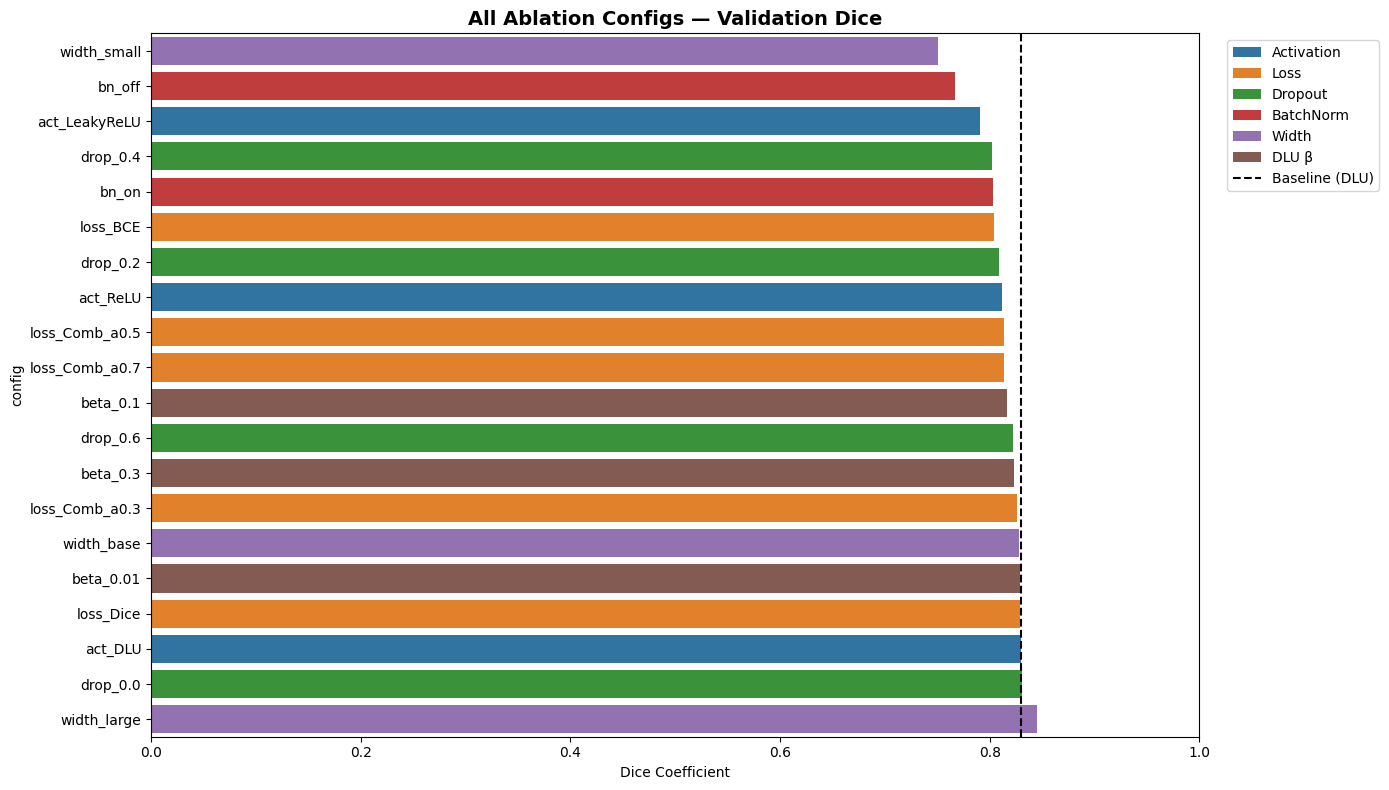

In [24]:
# ============================================================
# MASTER ABLATION SUMMARY
# ============================================================
axis_files = {
    "Activation": csv_act,
    "Loss":       csv_loss,
    "Dropout":    csv_dr,
    "BatchNorm":  csv_bn,
    "Width":      csv_w,
    "DLU β":      csv_b,
}

master_rows = []
for axis, fp in axis_files.items():
    if os.path.exists(fp):
        d = pd.read_csv(fp)
        d["axis"] = axis
        master_rows.append(d)

master = pd.concat(master_rows, ignore_index=True)
master_path = os.path.join(ABLATION_DIR, "master.csv")
master.to_csv(master_path, index=False)
sync_to_drive()

print("\n" + "="*80)
print("📊 MASTER ABLATION TABLE")
print("="*80)
print(master.sort_values(["axis","dice"], ascending=[True, False])
            .to_string(index=False, float_format="%.4f"))

# Global overview: Dice bar chart
plt.figure(figsize=(14, 8))
order = master.sort_values("dice", ascending=True)["config"].tolist()
sns.barplot(data=master, y="config", x="dice", hue="axis",
            order=order, dodge=False, palette="tab10")
plt.axvline(x=master[master["config"]=="act_DLU"]["dice"].values[0],
            color='k', ls='--', lw=1.5, label='Baseline (DLU)')
plt.title("All Ablation Configs — Validation Dice", fontsize=14, fontweight='bold')
plt.xlabel("Dice Coefficient")
plt.xlim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

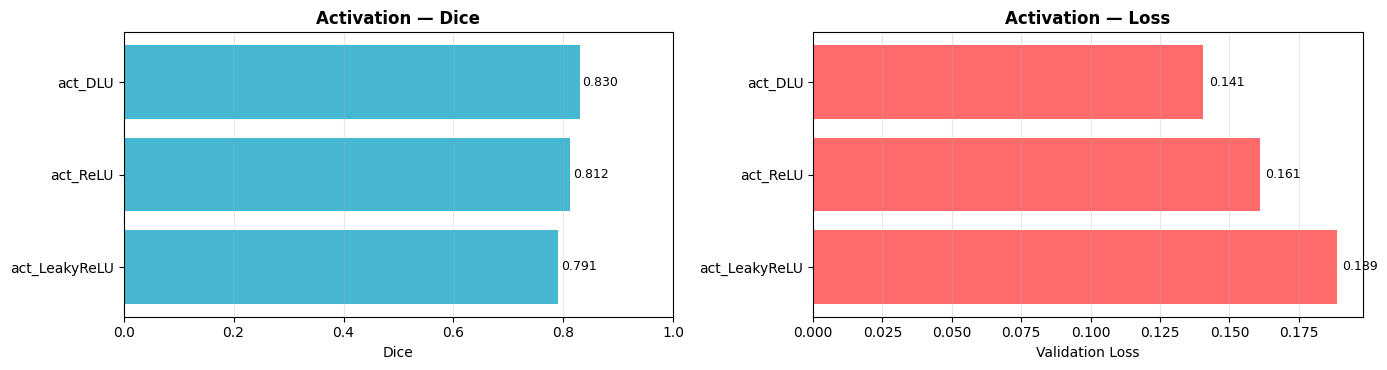

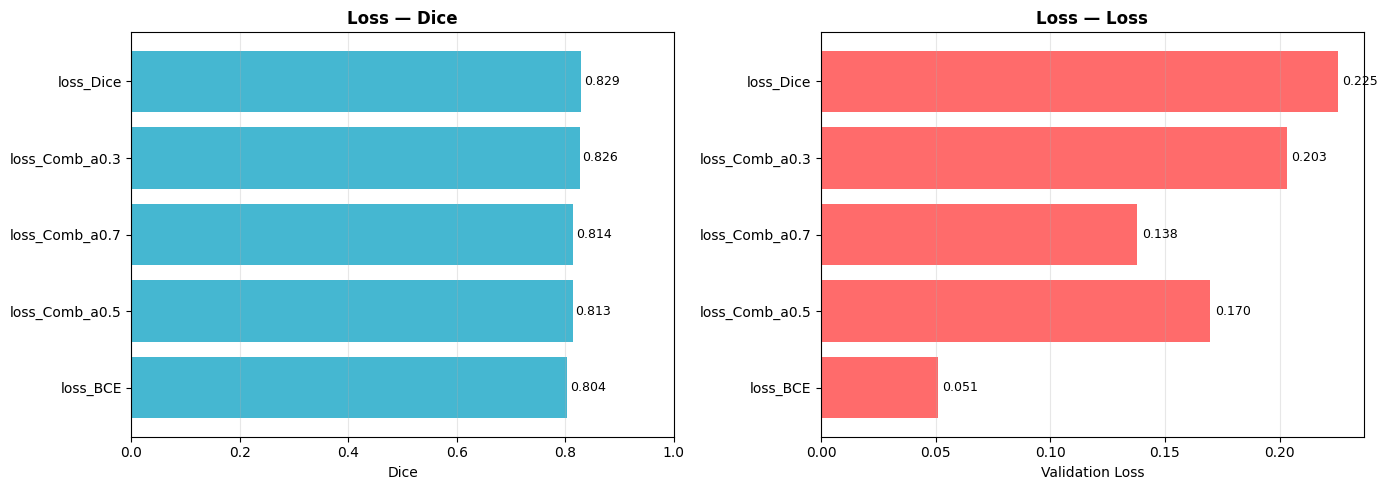

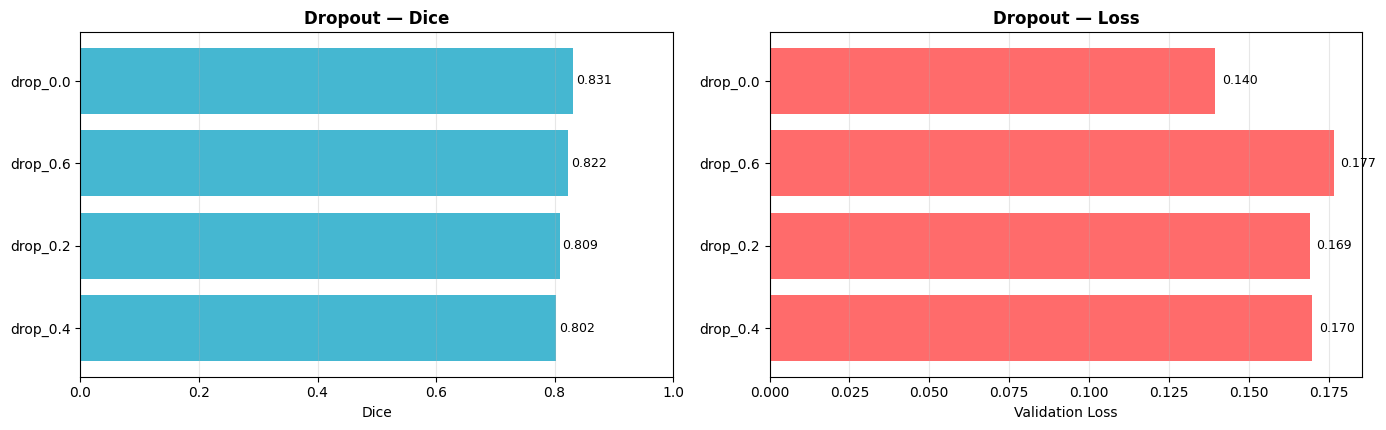

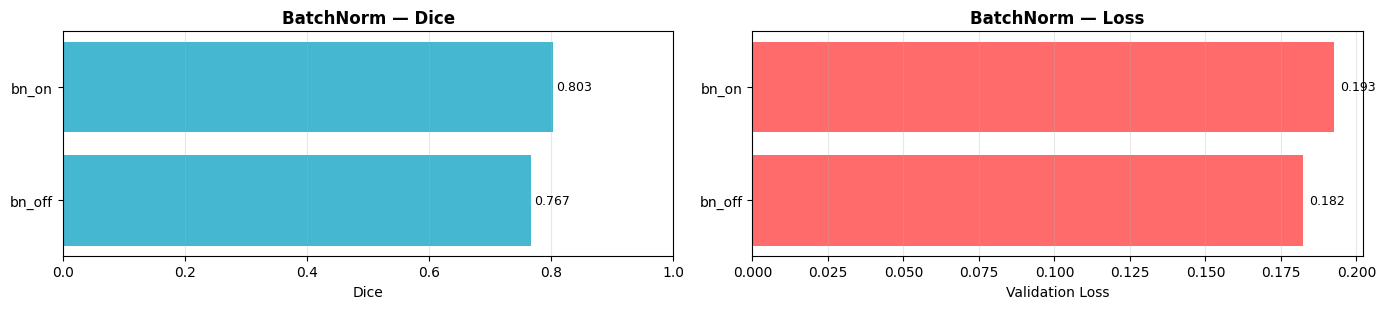

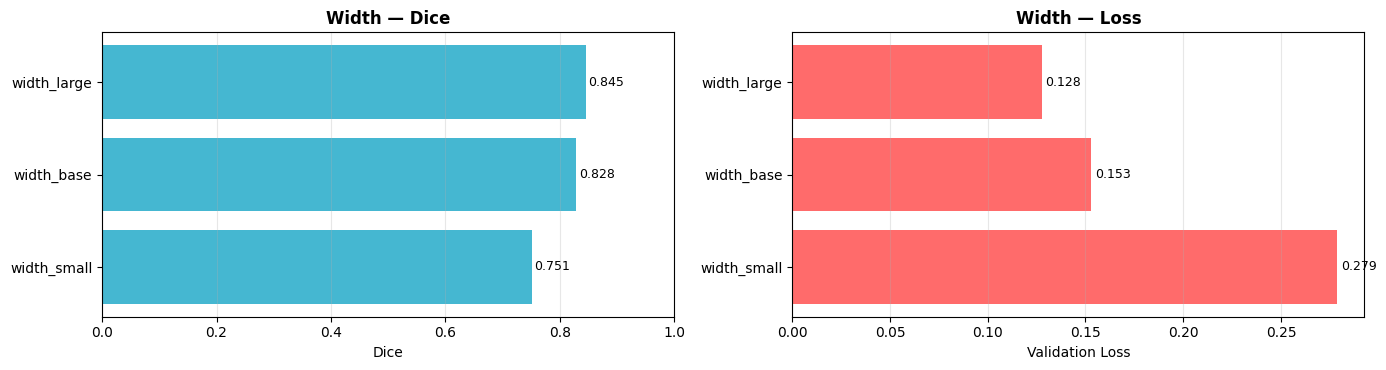

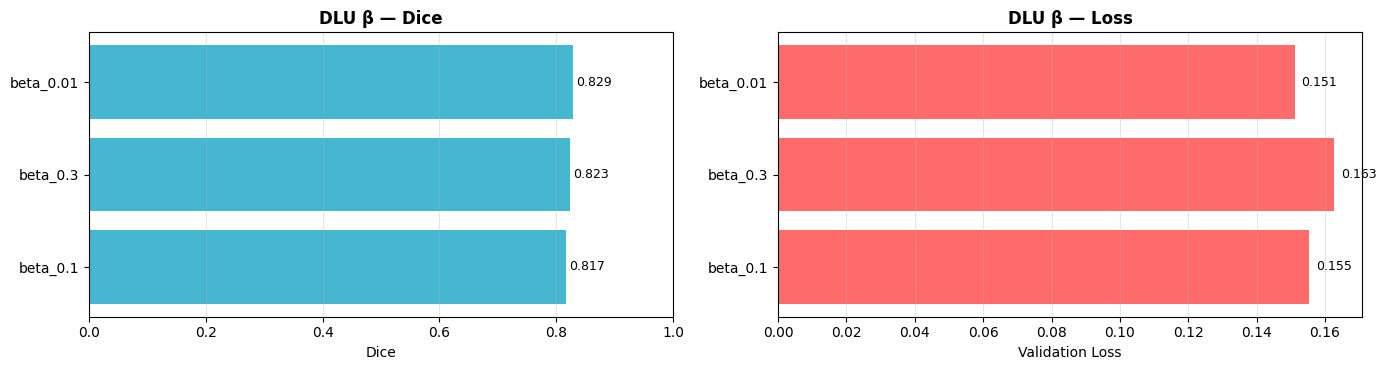

In [25]:
# ============================================================
# PER-AXIS BAR CHARTS (Dice + Loss)
# ============================================================
def plot_axis(df, axis_name):
    d = df.sort_values("dice", ascending=True)
    fig, ax = plt.subplots(1, 2, figsize=(14, max(3, 0.6*len(d)+2)))

    # Dice
    bars = ax[0].barh(d["config"], d["dice"], color="#45B7D1")
    ax[0].set_xlim(0, 1)
    ax[0].set_xlabel("Dice")
    ax[0].set_title(f"{axis_name} — Dice", fontweight='bold')
    ax[0].grid(alpha=0.3, axis='x')
    for b, v in zip(bars, d["dice"]):
        ax[0].text(v + 0.005, b.get_y() + b.get_height()/2,
                   f"{v:.3f}", va='center', fontsize=9)

    # Loss
    bars = ax[1].barh(d["config"], d["loss"], color="#FF6B6B")
    ax[1].set_xlabel("Validation Loss")
    ax[1].set_title(f"{axis_name} — Loss", fontweight='bold')
    ax[1].grid(alpha=0.3, axis='x')
    for b, v in zip(bars, d["loss"]):
        ax[1].text(v + 0.002, b.get_y() + b.get_height()/2,
                   f"{v:.3f}", va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

for axis, fp in axis_files.items():
    if os.path.exists(fp):
        plot_axis(pd.read_csv(fp), axis)

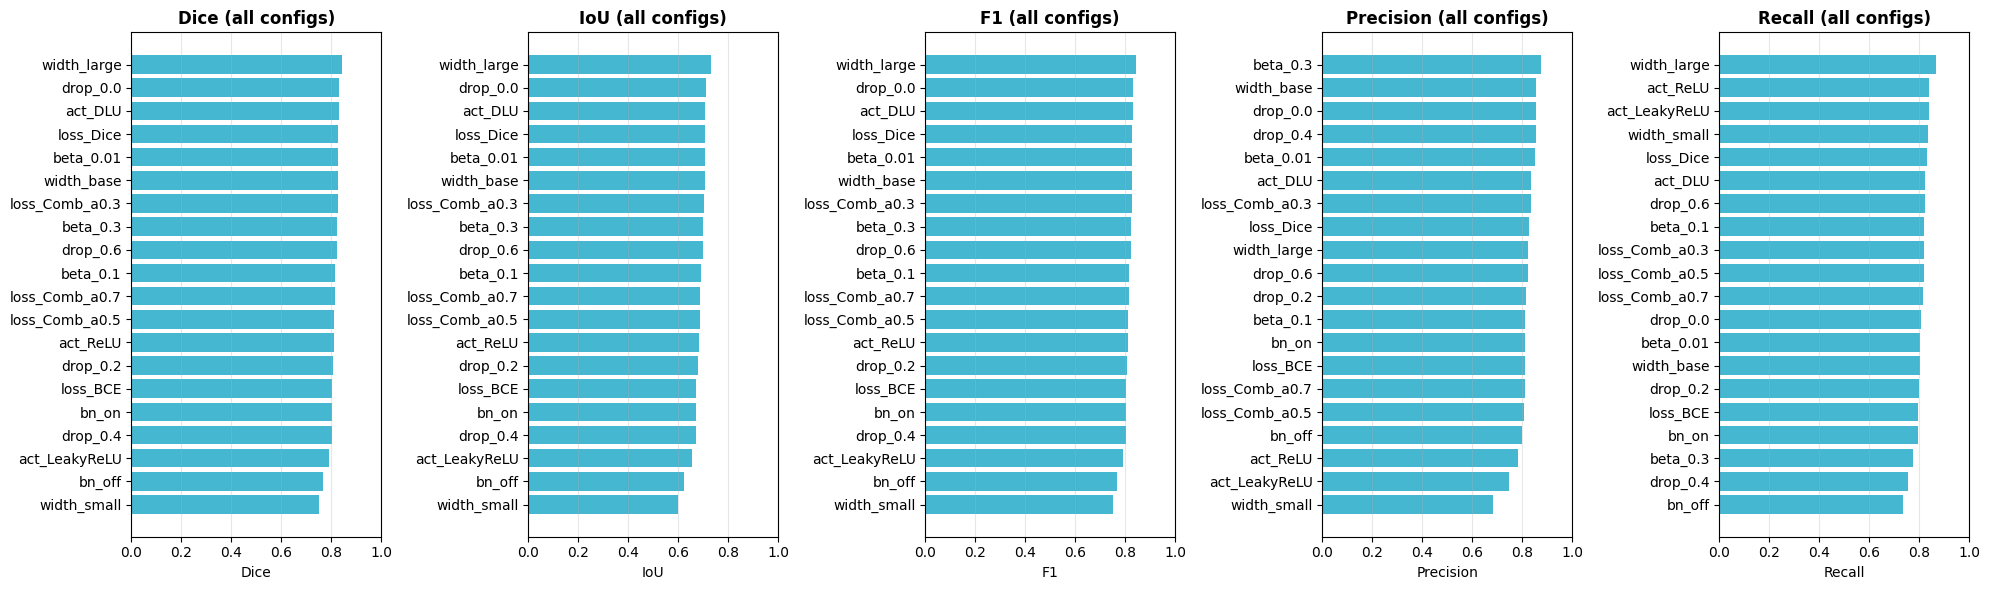

In [26]:
# ============================================================
# CROSS-AXIS METRIC COMPARISON (Dice / IoU / F1 / Precision / Recall)
# ============================================================
if len(master) > 0:
    metrics = ["dice", "iou", "f1", "precision", "recall"]
    labels  = ["Dice", "IoU", "F1", "Precision", "Recall"]

    fig, axes = plt.subplots(1, len(metrics), figsize=(20, 6), sharey=False)
    for ax, met, lab in zip(axes, metrics, labels):
        d = master.sort_values(met, ascending=True)
        ax.barh(d["config"], d[met], color="#45B7D1")
        ax.set_xlabel(lab)
        ax.set_title(f"{lab} (all configs)", fontweight='bold')
        ax.set_xlim(0, 1)
        ax.grid(alpha=0.3, axis='x')

    plt.tight_layout()
    plt.show()

In [27]:
# ============================================================
# PAIRED T-TEST: EACH CONFIG vs BASELINE (act_DLU)
# ============================================================
def paired_test_vs_baseline(master_df, baseline="act_DLU", metric="dice"):
    """Do not interpret a single-run result as statistically significant. Repeated paired runs are required."""
    base_rows = master_df[master_df["config"] == baseline]
    if len(base_rows) < 2:
        print(f"⚠️  Need ≥2 runs of '{baseline}' to run paired tests "
              f"(currently {len(base_rows)}). Skipping.")
        return

    print(f"\n🔬 Paired t-test vs baseline '{baseline}' (metric={metric})")
    print("="*70)
    for cfg in master_df["config"].unique():
        if cfg == baseline:
            continue
        other_rows = master_df[master_df["config"] == cfg]
        if len(other_rows) == len(base_rows):
            t, p = ttest_rel(base_rows[metric].values, other_rows[metric].values)
            sig = "**" if p < 0.05 else "  "
            print(f"  {baseline} vs {cfg:25s}  t={t:+.3f}  p={p:.4f} {sig}")

paired_test_vs_baseline(master, baseline="act_DLU", metric="dice")

⚠️  Need ≥2 runs of 'act_DLU' to run paired tests (currently 1). Skipping.


In [28]:
# ============================================================
# FINAL — ABLATION SUMMARY
# ============================================================
print("\n" + "="*80)
print("✅ ABLATION STUDY COMPLETE")
print("="*80)
print(f"\n📁 CSV results : {ABLATION_DIR}/")
print(f"📁 Checkpoints : {CKPT_DIR}/")
print(f"📁 Drive backup: {DRIVE_OUT}/")

print(f"\n📊 Configs run: {len(master)}")
print(f"⏱️  Total time : {master['minutes'].sum():.1f} minutes "
      f"({master['minutes'].sum()/60:.2f} hours)")

# Best config per axis
print("\n🏆 Highest validation Dice per axis (exploratory; not test performance):")
for axis in master["axis"].unique():
    sub = master[master["axis"] == axis].sort_values("dice", ascending=False)
    if len(sub) > 0:
        top = sub.iloc[0]
        print(f"  {axis:12s} → {top['config']:22s} "
              f"Dice={top['dice']:.4f}  IoU={top['iou']:.4f}  F1={top['f1']:.4f}")

# Overall best
best = master.sort_values("dice", ascending=False).iloc[0]
print(f"\n🥇 HIGHEST VALIDATION DICE (selection only): {best['config']}")
print(f"   Dice={best['dice']:.4f}  IoU={best['iou']:.4f}  "
      f"Precision={best['precision']:.4f}  Recall={best['recall']:.4f}  "
      f"F1={best['f1']:.4f}")


✅ ABLATION STUDY COMPLETE

📁 CSV results : ablation_results/
📁 Checkpoints : ablation_ckpts/
📁 Drive backup: /content/drive/MyDrive/litnet_ablation/

📊 Configs run: 20
⏱️  Total time : 15.2 minutes (0.25 hours)

🏆 Highest validation Dice per axis (exploratory; not test performance):
  Activation   → act_DLU                Dice=0.8297  IoU=0.7090  F1=0.8297
  Loss         → loss_Dice              Dice=0.8291  IoU=0.7081  F1=0.8291
  Dropout      → drop_0.0               Dice=0.8310  IoU=0.7109  F1=0.8310
  BatchNorm    → bn_on                  Dice=0.8030  IoU=0.6709  F1=0.8030
  Width        → width_large            Dice=0.8451  IoU=0.7318  F1=0.8451
  DLU β        → beta_0.01              Dice=0.8286  IoU=0.7073  F1=0.8286

🥇 HIGHEST VALIDATION DICE (selection only): width_large
   Dice=0.8451  IoU=0.7318  Precision=0.8246  Recall=0.8666  F1=0.8451
